Dataset Loaded Successfully!
Features: (569, 30)
Target: (569, 1)
Class Names: ['malignant' 'benign']

Training Samples: 426
Testing Samples: 143

DNN TRAINING STARTED
Epoch: 1 | Loss: 0.674832 | Accuracy: 62.68 %
Epoch: 200 | Loss: 0.458934 | Accuracy: 85.92 %
Epoch: 400 | Loss: 0.256185 | Accuracy: 94.84 %
Epoch: 600 | Loss: 0.15992 | Accuracy: 96.48 %
Epoch: 800 | Loss: 0.11677 | Accuracy: 97.89 %
Epoch: 1000 | Loss: 0.094798 | Accuracy: 98.12 %

TRAINING COMPLETED

Final Test Loss: 0.104868
Test Accuracy: 98.6 %

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143


FINAL PREDICTIONS
Sample 1 | Probability: 0.9399 | Actual: benign | Predicted: benign
Sample 2 | Probability: 0.0469 | Actual:

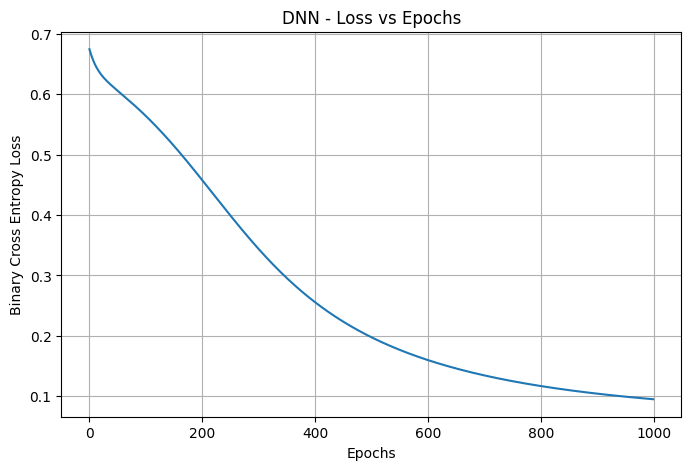

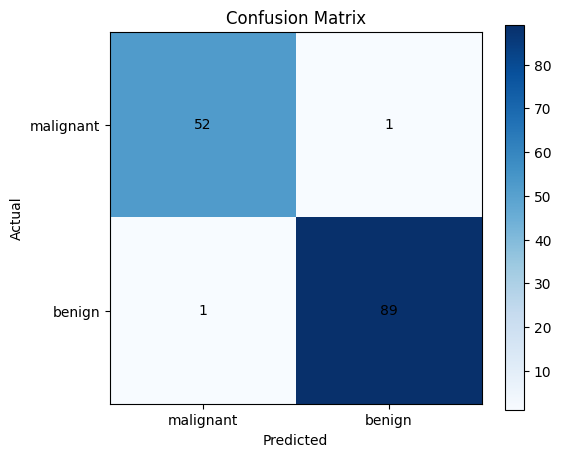


DNN Classification Completed Successfully!


In [ ]:
# DLL Experiment No. 5
# Fully Connected Deep Neural Network for Classification

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# 1. Load Dataset
data = load_breast_cancer()

X = data.data
Y = data.target.reshape(-1, 1)

print("Dataset Loaded Successfully!")
print("Features:", X.shape)
print("Target:", Y.shape)

print("Class Names:", data.target_names)


# 2. Split Dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# 3. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# 4. Initialize Network Architecture
input_neurons = X_train.shape[1]
hidden1_neurons = 16
hidden2_neurons = 8
output_neurons = 1

rng = np.random.default_rng(42)


# Xavier Weight Initialization
def initialize_weights(fan_in, fan_out):

    limit = np.sqrt(6 / (fan_in + fan_out))

    return rng.uniform(
        -limit, limit,
        (fan_in, fan_out)
    )


W1 = initialize_weights(input_neurons, hidden1_neurons)
W2 = initialize_weights(hidden1_neurons, hidden2_neurons)
W3 = initialize_weights(hidden2_neurons, output_neurons)

# Initialize Biases
b1 = np.zeros((1, hidden1_neurons))
b2 = np.zeros((1, hidden2_neurons))
b3 = np.zeros((1, output_neurons))


# Save Initial Weights
initial_W1 = W1.copy()
initial_W2 = W2.copy()
initial_W3 = W3.copy()


# 5. Sigmoid Activation Function
def sigmoid(x):

    x = np.clip(x, -500, 500)

    return 1 / (1 + np.exp(-x))


# 6. Binary Cross Entropy Loss
def binary_cross_entropy(y, prediction):

    prediction = np.clip(
        prediction, 1e-10, 1 - 1e-10
    )

    return -np.mean(
        y * np.log(prediction)
        + (1 - y) * np.log(1 - prediction)
    )


# 7. Training Parameters
learning_rate = 0.05
epochs = 1000

error_list = []

print("\n================================")
print("DNN TRAINING STARTED")
print("================================")


# 8. Training using Backpropagation
for epoch in range(1, epochs + 1):

    # FORWARD PROPAGATION

    Z1 = np.dot(X_train, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    Z3 = np.dot(A2, W3) + b3
    prediction = sigmoid(Z3)

    # Calculate Loss
    loss = binary_cross_entropy(Y_train, prediction)

    m = len(X_train)


    # BACKPROPAGATION

    # Output Layer
    dZ3 = (prediction - Y_train) / m

    dW3 = np.dot(A2.T, dZ3)
    db3 = np.sum(dZ3, axis=0, keepdims=True)


    # Hidden Layer 2
    dA2 = np.dot(dZ3, W3.T)

    dZ2 = dA2 * A2 * (1 - A2)

    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)


    # Hidden Layer 1
    dA1 = np.dot(dZ2, W2.T)

    dZ1 = dA1 * A1 * (1 - A1)

    dW1 = np.dot(X_train.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)


    # UPDATE WEIGHTS AND BIASES

    W3 = W3 - learning_rate * dW3
    b3 = b3 - learning_rate * db3

    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1


    # Store Loss
    error_list.append(loss)


    # Display Training Progress
    if epoch == 1 or epoch % 200 == 0:

        predicted_classes = (prediction >= 0.5).astype(int)

        accuracy = np.mean(
            predicted_classes == Y_train
        ) * 100

        print(
            "Epoch:", epoch,
            "| Loss:", round(loss, 6),
            "| Accuracy:", round(accuracy, 2), "%"
        )


# 9. Final Predictions on Test Dataset

Z1 = np.dot(X_test, W1) + b1
A1 = sigmoid(Z1)

Z2 = np.dot(A1, W2) + b2
A2 = sigmoid(Z2)

Z3 = np.dot(A2, W3) + b3
final_prediction = sigmoid(Z3)

predicted_classes = (final_prediction >= 0.5).astype(int)


# 10. Model Performance

accuracy = accuracy_score(Y_test, predicted_classes)

final_loss = binary_cross_entropy(
    Y_test, final_prediction
)

print("\n================================")
print("TRAINING COMPLETED")
print("================================")

print("\nFinal Test Loss:", round(final_loss, 6))

print("Test Accuracy:", round(accuracy * 100, 2), "%")


print("\nClassification Report:")

print(
    classification_report(
        Y_test,
        predicted_classes,
        target_names=data.target_names
    )
)


# 11. Display Predictions

print("\n================================")
print("FINAL PREDICTIONS")
print("================================")

for i in range(min(10, len(X_test))):

    probability = final_prediction[i][0]

    actual = int(Y_test[i][0])
    predicted = int(predicted_classes[i][0])

    result = data.target_names[predicted]

    print(
        "Sample", i + 1,
        "| Probability:", round(probability, 4),
        "| Actual:", data.target_names[actual],
        "| Predicted:", result
    )


# 12. Random Sample Prediction

sample_index = rng.integers(0, len(X_test))

probability = final_prediction[sample_index][0]

print("\n================================")
print("RANDOM SAMPLE PREDICTION")
print("================================")

print("Prediction Probability:", round(probability, 4))

if probability >= 0.5:

    print("Predicted Class: BENIGN")

else:

    print("Predicted Class: MALIGNANT")


# 13. Updated Weights

print("\n================================")
print("UPDATED WEIGHTS")
print("================================")

print("W1 Shape:", W1.shape)
print("W2 Shape:", W2.shape)
print("W3 Shape:", W3.shape)

print("\nChange in W1:")
print(np.round(W1 - initial_W1, 4))

print("\nChange in W2:")
print(np.round(W2 - initial_W2, 4))

print("\nChange in W3:")
print(np.round(W3 - initial_W3, 4))


# 14. Loss vs Epochs Graph

plt.figure(figsize=(8, 5))

plt.plot(error_list)

plt.title("DNN - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy Loss")

plt.grid(True)
plt.show()


# 15. Confusion Matrix

cm = confusion_matrix(Y_test, predicted_classes)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], data.target_names)
plt.yticks([0, 1], data.target_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

for i in range(2):

    for j in range(2):

        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.show()


print("\nDNN Classification Completed Successfully!")